<h2 style= "color: #60A5FA; text-align: left; font-weight: bold;">
Regional Crime Pattern Analysis
</h2>

<h3 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
1. Business Understanding
</h3>
A public policy research firm seeks to identify and understand patterns in crime statistics across different regions. By analysing regional crime data, the firm aims to uncover similarities and differences in crime characteristics that may support more informed policy research and decision-making.

The objective of this project is to apply feature selection, Principal Component Analysis (PCA), K-Means clustering, and Gaussian Mixture Models (GMM) to group regions based on their crime profiles.

K-Means will be used to assign each region to a single cluster (hard clustering), while GMM will estimate the probability of each region belonging to different clusters (probabilistic clustering).

The resulting clusters will provide insights into regional crime patterns, helping identify groups of regions with similar crime characteristics and supporting further investigation into regional crime trends and policy priorities.

<h3 style="color: #9CA3AF; text-align: left; font-weight: bold;">
2.Data Understanding
<h3>

In [1]:
#import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib as plt

#Load the dataset
crime_df=pd.read_csv("USArrests.csv")

#check the first five rows
crime_df.head()

,rownames,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0
3,Arkansas,8.8,190,50,19.5
4,California,9.0,276,91,40.6



<h3 style="color: #9CA3AF; text-align: left; font-weight: bold; font-size: 16px;">
Data Understanding
</h3>

The USArrests dataset is loaded into a Pandas DataFrame for analysis. It contains crime statistics and urban population information for different states in the United States.

The following Python libraries are imported:

- **Pandas:** Used for loading and manipulating the dataset.
- **NumPy:** Supports numerical computations.
- **Matplotlib:** Used for creating data visualisations.

The dataset is loaded from the `USArrests.csv` file using `pd.read_csv()`. The `head()` function displays the first five observations to provide an initial overview of the dataset.

The dataset contains the following variables:

| Variable | Description |
|---|---|
| `rownames` | Identifies the state |
| `Murder` | Murder statistics |
| `Assault` | Assault statistics |
| `UrbanPop` | Urban population statistics |
| `Rape` | Rape statistics |

The initial inspection provides an overview of the dataset's structure and variables before proceeding with data cleaning, exploratory analysis, and feature selection.

**Note:** The `rownames` column serves as a state identifier and will not be treated as a numerical feature during clustering.



In [2]:
crime_df.shape

(50, 5)

In [3]:
crime_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  50 non-null     object 
 1   Murder    50 non-null     float64
 2   Assault   50 non-null     int64  
 3   UrbanPop  50 non-null     int64  
 4   Rape      50 non-null     float64
dtypes: float64(2), int64(2), object(1)
memory usage: 2.1+ KB


In [4]:
#Descriptive statistics for the dataset
crime_df.describe()

,Murder,Assault,UrbanPop,Rape
count,50.00000,50.000000,50.000000,50.000000
mean,7.78800,170.760000,65.540000,21.232000
std,4.35551,83.337661,14.474763,9.366385
min,0.80000,45.000000,32.000000,7.300000
25%,4.07500,109.000000,54.500000,15.075000
50%,7.25000,159.000000,66.000000,20.100000
75%,11.25000,249.000000,77.750000,26.175000
max,17.40000,337.000000,91.000000,46.000000


In [7]:
crime_df.isnull().sum()

rownames    0
Murder      0
Assault     0
UrbanPop    0
Rape        0
dtype: int64

In [8]:
#Check for duplicates
crime_df.duplicated().sum()

np.int64(0)


<h3 style="color: #9CA3AF; text-align: left; font-weight: bold; font-size: 16px;">
2.2 Descriptive Statistics and Findings
</h3>

The dataset is examined to understand its dimensions, data types, completeness, and statistical characteristics.

**Dataset dimensions**

The `shape` attribute confirms that the dataset contains **50 observations and 5 columns**, with each observation representing a US state.

**Dataset information**

The `info()` function shows that all five columns contain 50 non-null values, indicating no missing values. The `rownames` column has an object data type, while the remaining four variables are numerical.

**Descriptive statistics**

The `describe()` function provides summary statistics, including the mean, standard deviation, minimum, maximum, and quartiles.

Key observations from the numerical variables include:

- **Murder:** Mean of 7.79, ranging from 0.8 to 17.4.
- **Assault:** Mean of 170.76, ranging from 45 to 337.
- **UrbanPop:** Mean of 65.54, ranging from 32 to 91.
- **Rape:** Mean of 21.23, ranging from 7.3 to 46.0.

**Initial findings**

The dataset contains no missing values, and all four analytical variables are numerical. However, the variables have considerably different numerical ranges. This is important because distance-based algorithms such as K-Means are sensitive to feature scales. Standardisation will therefore be considered before applying PCA and clustering.




<h3 style="color: #9CA3AF; text-align: left; font-weight: bold;">
3. Data Preparation
</h3>

<h4 style="color: #9CA3AF; text-align: left; font-weight: bold;">
3.1 Feature Selection
</h4>

Three variables, `Murder`, `Assault`, and `Rape`, are selected as the features for clustering because they directly represent different categories of crime. These variables provide the basis for identifying similarities and differences in crime patterns across states.

The `UrbanPop` variable is excluded because it represents the percentage of the population living in urban areas rather than a direct measure of crime. Its exclusion allows the clustering analysis to focus specifically on crime-related characteristics.


In [9]:
# Feature selection

features = ['Murder', 'Assault', 'Rape']

X = crime_df[features]

# Display the selected features
X.head()

,Murder,Assault,Rape
0,13.2,236,21.2
1,10.0,263,44.5
2,8.1,294,31.0
3,8.8,190,19.5
4,9.0,276,40.6



<h4 style="color: #9CA3AF; text-align: left; font-weight: bold;">
3.2 Feature Standardization
</h4>

The selected features have different numerical scales and ranges. Standardization is applied to transform the variables to a common scale, ensuring that features with larger values do not disproportionately influence the analysis.

This process transforms each feature to have a mean of approximately 0 and a standard deviation of 1. It is particularly important for distance-based algorithms such as K-Means and for PCA, where differences in feature scales can affect the results.


In [11]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Standardize the selected features
X_scaled = scaler.fit_transform(X)

# Convert the standardized data back to a DataFrame
X_scaled = pd.DataFrame(X_scaled, columns=features, index=X.index)

# Preview the standardized features
X_scaled.head()

,Murder,Assault,Rape
0,1.255179,0.790787,-0.003451
1,0.513019,1.118060,2.509424
2,0.072361,1.493817,1.053466
3,0.234708,0.233212,-0.186794
4,0.281093,1.275635,2.088814



<h4 style="color: #9CA3AF; text-align: left; font-weight: bold;">
3.3 Principal Component Analysis (PCA)
</h4>

Principal Component Analysis (PCA) is applied to reduce the three standardized crime features into two principal components. These components capture as much of the variation in the original data as possible while reducing the dimensionality of the dataset.

The reduction to two dimensions simplifies the representation of the data and makes it possible to visualise the regional crime patterns on a two-dimensional plot. The transformed features will also be used as inputs for the clustering algorithms.


In [12]:
from sklearn.decomposition import PCA

# Initialize PCA with two components
pca = PCA(n_components=2)

# Transform the standardized features
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame of the principal components
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2'],
    index=X_scaled.index
)

# Display the transformed data
pca_df.head()

,PC1,PC2
0,1.210191,-0.842277
1,2.332187,1.539434
2,1.518593,0.503363
3,0.177776,-0.328029
4,2.066000,1.285497


In [13]:
# Calculate the explained variance ratio
explained_variance = pca.explained_variance_ratio_

print("Explained variance:", explained_variance)
print("Total explained variance:", explained_variance.sum())

Explained variance: [0.7861934  0.15268378]
Total explained variance: 0.9388771782627572



**PCA Findings**

The first two principal components explain approximately **93.89% of the total variance** in the selected crime features. This indicates that the two-dimensional representation preserves most of the information contained in the original `Murder`, `Assault`, and `Rape` variables.

The high cumulative explained variance suggests that reducing the data to two dimensions provides a useful representation for subsequent clustering analysis and visualisation, with relatively little information loss.



<h3 style="color: #9CA3AF; text-align: left; font-weight: bold;">
4. Determining the Optimal Number of Clusters
</h3>

Before fitting the final clustering models, different numbers of clusters are evaluated to determine the most appropriate grouping of regions. The Elbow Method is used to assess the optimal number of clusters for K-Means, while the Bayesian Information Criterion (BIC) is used to guide the selection of the number of components for the Gaussian Mixture Model (GMM).


<h4 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
4.1. K-Means Elbow Method
</h4>

In [14]:
from sklearn.cluster import KMeans

inertias = []
k_values = range(1, 11)

# we train the kmeans repeatedly and for each model we record inertia, to measure how tightly observations 
# are grouped around their cluster centers

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_pca)
    inertias.append(kmeans.inertia_)

c:\Users\zaina\anaconda3\envs\ml-env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\zaina\anaconda3\envs\ml-env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\zaina\anaconda3\envs\ml-env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\zaina\anaconda3\envs\ml-env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

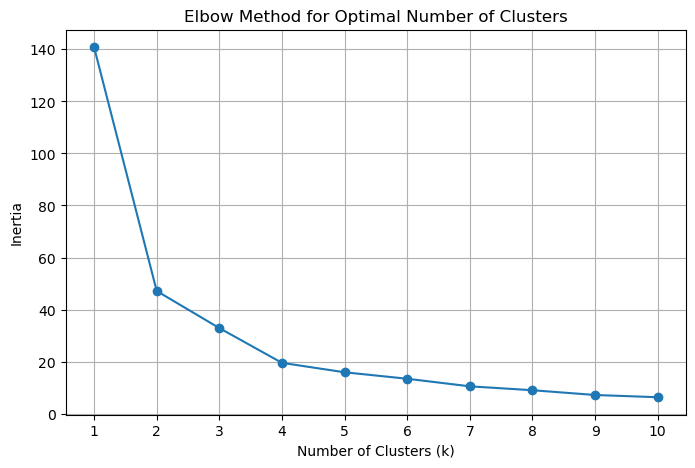

In [15]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker='o')

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal Number of Clusters')
plt.xticks(k_values)
plt.grid(True)

plt.show()



**K-Means Elbow Findings**

The inertia decreases substantially as the number of clusters increases from 1 to 4. Beyond approximately 4 clusters, the reduction in inertia becomes more gradual. This suggests that adding more clusters provides diminishing improvements in within-cluster compactness. Therefore, 4 clusters are selected for the K-Means model.

**GMM BIC Findings**

The Bayesian Information Criterion (BIC) reaches its lowest value at 2 components. Since a lower BIC indicates a preferred balance between model fit and complexity, a 2-component Gaussian Mixture Model is selected for the subsequent analysis.



<h4 style="color: #9CA3AF; text-align: left; font-weight: bold;">
4.2. GMM using BIC
</h4>

Similar to K-Means, different numbers of components ranging from 1 to 10 are evaluated for the Gaussian Mixture Model (GMM). However, instead of inertia, the Bayesian Information Criterion (BIC) is used to assess model performance.

BIC considers both how well the model fits the data and its complexity, penalising models with unnecessary parameters. A lower BIC value indicates a preferred model, providing a balance between goodness of fit and model complexity.


In [16]:
from sklearn.mixture import GaussianMixture

bic_scores = []
cluster_range = range(1, 11)

for n in cluster_range:
    gmm = GaussianMixture(
        n_components=n,
        random_state=42
    )
    
    gmm.fit(X_pca)
    bic_scores.append(gmm.bic(X_pca))

c:\Users\zaina\anaconda3\envs\ml-env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\zaina\anaconda3\envs\ml-env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\zaina\anaconda3\envs\ml-env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\zaina\anaconda3\envs\ml-env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

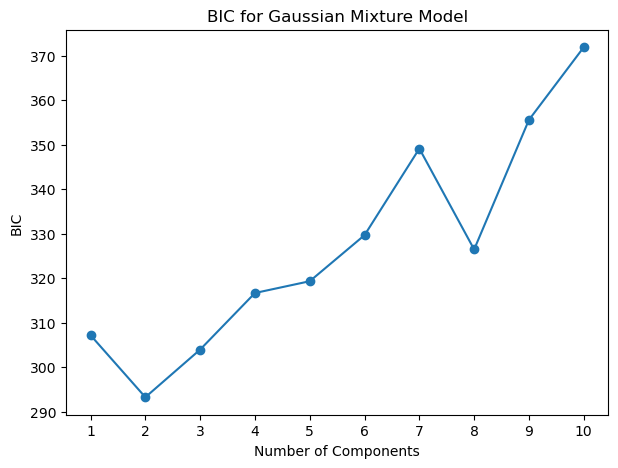

In [17]:
# visualization
plt.figure(figsize=(7, 5))

plt.plot(cluster_range, bic_scores, marker="o")

plt.xlabel("Number of Components")
plt.ylabel("BIC")
plt.title("BIC for Gaussian Mixture Model")
plt.xticks(cluster_range)
plt.show()


**GMM BIC Findings**

The Bayesian Information Criterion (BIC) reaches its lowest value at 2 components. Since a lower BIC indicates a better balance between model fit and complexity, a 2-component Gaussian Mixture Model is selected as the preferred configuration for the subsequent analysis.


<h3 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
5. Clustering Models
</h3>

K-Means and Gaussian Mixture Models are applied to the PCA-transformed data using the number of clusters identified by the Elbow Method and BIC respectively

<h4 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
5.1. K-Means
</h4>

In [18]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

pca_df["KMeans_Cluster"] = kmeans.fit_predict(X_pca)

c:\Users\zaina\anaconda3\envs\ml-env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [19]:
gmm = GaussianMixture(
    n_components=2,
    random_state=42
)

pca_df["GMM_Cluster"] = gmm.fit_predict(X_pca)  

c:\Users\zaina\anaconda3\envs\ml-env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


<h3 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
6. Clustering Results and Visualization
</h3>

The clustering results are visualized using the two principal components. This allows the cluster structures identified by K-Means and GMM to be compared.

<h4 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
6.1. K-Means Visualization
</h4>

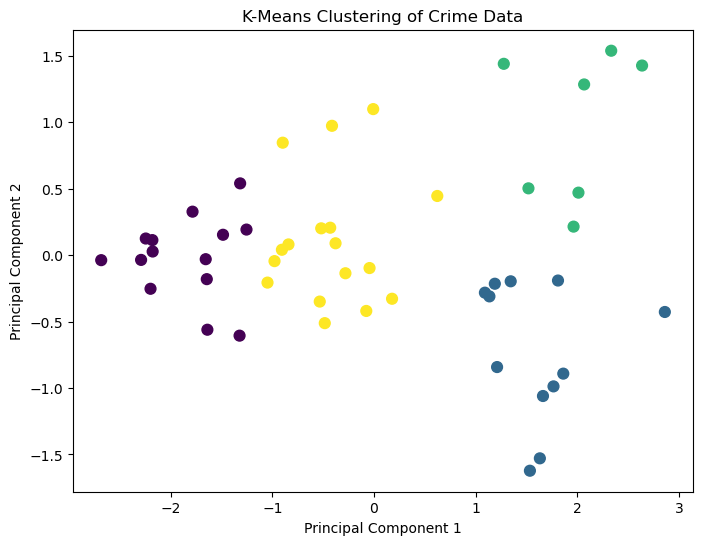

In [20]:
plt.figure(figsize=(8, 6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["KMeans_Cluster"],
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of Crime Data")
plt.show()

<h4 style= "color: #9CA3AF; text-align: left; font-weight: bold;">
6.2. GMM Visualization
</h4>

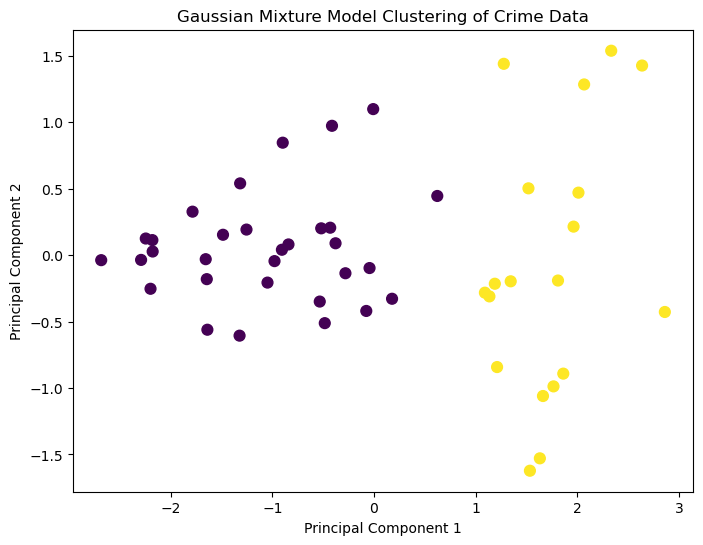

In [21]:
plt.figure(figsize=(8, 6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["GMM_Cluster"],
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Gaussian Mixture Model Clustering of Crime Data")
plt.show()


<h4 style="color: #9CA3AF; text-align: left; font-weight: bold;">
Comparison of Clustering Results
</h4>

The K-Means model separates the states into four distinct clusters, providing a more detailed segmentation of regional crime patterns. The clusters are primarily separated along the first principal component (PC1), with additional separation along the second principal component (PC2).

The GMM produces two broader groups of states, consistent with the two-component solution selected using BIC. Unlike K-Means, which assigns each state to a single cluster, GMM provides probabilistic cluster membership, estimating the likelihood of each state belonging to each component.

Overall, both methods reveal different levels of structure within the same crime dataset. K-Means identifies four more granular groups, while GMM provides a broader two-component representation of regional crime patterns.
